# Annealing chicken DT40 chromosome 7 at 50 kb

Can a simulated mitotic chromosome contain turns on more than one genomic scale? We cool a chromosome 7 model using the 15-minute interaction parameters, then compare its orientation spectrum with that of an archived 15-minute conformation.

Select the `openmichrom-tutorials` kernel and run all cells. The default is a short CPU run; the structures and parameter tables are in the adjacent `input/` folder.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.signal import find_peaks
from OpenMiChroM.ChromDynamics import MiChroM
from OpenMiChroM.CndbTools import CndbTools

default_run = "slow" if os.getenv("OPENMICHROM_TUTORIAL_MODE") == "full" else "compact"
RUN = os.getenv("OPENMICHROM_DT40_RUN", default_run)  # or set RUN = 'extended' here
SEED = int(os.getenv("OPENMICHROM_DT40_SEED", "15050"))
PLATFORM = os.getenv("OPENMICHROM_TUTORIAL_PLATFORM", "CPU")
BIN_MB = 0.050

folders = (Path("."), Path("DT40_Annealing_50kb"), Path("Tutorials/DT40_Annealing_50kb"))
data = next((p / "input" for p in folders if (p / "input/chr7_15m-Q.gro").is_file()), None)
if data is None:
    raise FileNotFoundError("Open the notebook folder with its adjacent input/ directory.")
sequence = data / "DT40_chr7.txt"

## 1. Anneal the chain

For the short run, start from `chr7_10m-Q.gro`, an archived 10-minute conformation. Apply the **15-minute** interaction tables and cool from 2.0 to 0.2 in reduced temperature units. This is a change of model conditions, not a simulation of five minutes of cell-cycle time. The independent `chr7_15m-Q.gro` structure is reserved for comparison.

The default `compact` schedule takes 2,600 steps (about 13 seconds on an Apple M3 Max CPU, including plotting). Set `RUN = 'extended'` for a slower ramp from the same starting structure: 100 temperatures × 1,000 steps, then 30,000 steps at 0.2. Change `SEED` to compare replicas. To start from a straight chain instead, select `smoke` (160 steps) or `slow` (55,005,000 steps). For `slow`, allow about **two hours** on an Apple M3 Max GPU with `PLATFORM = 'OpenCL'`; other devices can differ. A short run does not establish convergence.

In [2]:
# Each schedule gives (temperature levels, MD steps per block, cold blocks).
schedules = {"compact": (16, 100, 10), "extended": (100, 1_000, 30),
             "smoke": (6, 20, 2), "slow": (10_000, 5_000, 1_001)}
n_ramp, steps, n_hold = schedules[RUN]
np.random.seed(SEED)
sim = MiChroM(name="DT40_chr7", temperature=1.0, timeStep=0.01, verbose=False)  # ps per MD step
sim.setup(platform=PLATFORM, precision="single" if PLATFORM.lower() == "opencl" else "mixed")

# Supply the A1/B1 annotation explicitly for these historical GRO residue labels.
if RUN in ("compact", "extended"):
    chain = sim.initStructure(CoordFiles=data / "chr7_10m-Q.gro", ChromSeq=sequence)
else:
    chain = sim.createLine(ChromSeq=sequence)
sim.loadStructure(chain, center=True)
sim.addHomoPolymerForces(softcoreLJ=True, kFb=30.0, kA=1.0, eCut=4.0)
sim.addCustomTypes(mu=1.51, rc=2.12, TypesTable=str(data / "lambdas_types_15m"))
sim.addCustomIC(mu=1.51, rc=2.12, dinit=3, dend=735, IClist=str(data / "lambdas_ic_15m"))

sim.integrator.setRandomNumberSeed(SEED)
with TemporaryDirectory() as work:
    sim.saveFolder(work)
    sim.createSimulation()
    sim.context.setVelocitiesToTemperature(sim.temperature, SEED)
    for temperature in np.linspace(2.0, 0.2, n_ramp):
        sim.integrator.setTemperature(temperature / 0.008314)  # reduced units to kelvin
        sim.run(nsteps=steps, report=False)
    save_at = set(np.linspace(1, n_hold, min(n_hold, 20), dtype=int))
    cold = []
    for block in range(1, n_hold + 1):
        sim.run(nsteps=steps, report=False)
        if block in save_at:
            cold.append(sim.getPositions().copy())

cold = np.stack(cold)
assert sim.simulation.currentStep == steps * (n_ramp + n_hold)
assert cold.shape[1:] == (739, 3) and np.isfinite(cold).all()
print(f"{RUN}, seed {SEED} on {sim.context.getPlatform().getName()}: {sim.simulation.currentStep:,} steps, {len(cold)} cold snapshots.")

Reading sequence in input/DT40_chr7.txt...


compact, seed 15050 on CPU: 2,600 steps, 10 cold snapshots.


## 2. Measure the helical periods

Read the **archived 15-minute structure** independently of the simulation above. The two views show the same coordinates, colored by genomic position.

Reading sequence in input/DT40_chr7.txt...


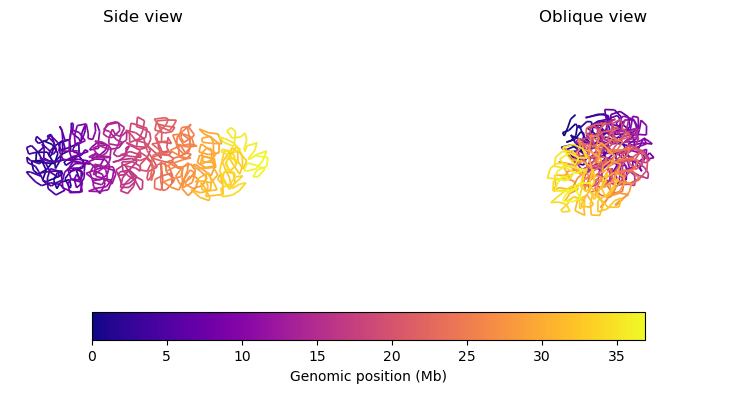

In [3]:
reference = MiChroM(verbose=False).initStructure(CoordFiles=data / "chr7_15m-Q.gro", ChromSeq=sequence)
assert reference.shape == cold.shape[1:] and np.isfinite(reference).all()
centered = reference - reference.mean(axis=0)
# Align the longest spatial axis to x for display only; the spectrum uses the original coordinates.
_, _, axes = np.linalg.svd(centered, full_matrices=False)
if np.linalg.det(axes) < 0:
    axes[-1] *= -1
display_xyz = centered @ axes.T
segments = np.stack((display_xyz[:-1], display_xyz[1:]), axis=1)
fig = plt.figure(figsize=(9, 3.8), layout="constrained")
for k, (elev, azim, title) in enumerate([(10, -85, "Side view"), (14, 8, "Oblique view")]):
    ax = fig.add_subplot(1, 2, k+1, projection="3d")
    line = Line3DCollection(segments, cmap="plasma", linewidths=1.25)
    line.set_array(np.arange(len(segments))*BIN_MB)
    ax.add_collection3d(line)
    lo, hi = display_xyz.min(axis=0), display_xyz.max(axis=0)
    ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), zlim=(lo[2], hi[2]), title=title)
    ax.set_box_aspect(hi-lo); ax.view_init(elev=elev, azim=azim); ax.set_axis_off()
fig.colorbar(line, ax=fig.axes[:], orientation="horizontal", shrink=0.62, label="Genomic position (Mb)")
plt.show()

Use `CndbTools` to correlate unit vectors joining beads $i$ and $i+4$ (200 kb). Each lag is normalized by its number of pairs; for the new run, average the correlations over cold frames **before** taking the Fourier transform.

Use the first half of the lags, subtract the mean and apply a Hann window. Divide the frequency in cycles per bead by 0.050 Mb to obtain cycles per Mb. Apply the same peak detector independently to both spectra; the archived peaks are marked on the plot. The reported periods are FFT-bin estimates, not fitted pitches.

In [4]:
reader = CndbTools()
def correlation(frame):
    return reader.compute_Orientation_OP(frame, chrom_end=None, vec_length=4, normalization="pairs")[1]
ref_op = correlation(reference)
new_op = np.mean([correlation(frame) for frame in cold], axis=0)
np.testing.assert_allclose([ref_op[0], new_op[0]], 1.0, atol=1e-6)
def spectrum(op):
    x = op[:len(op)//2]
    window = np.hanning(len(x))
    freq, amp = reader.compute_FFT_from_Oij((x-x.mean())*window, lowcut=None, highcut=None)
    return freq / BIN_MB, 2*amp/window.mean()
freq, amp_ref = spectrum(ref_op)
_, amp_new = spectrum(new_op)
def peak_bins(amplitude):
    peaks, props = find_peaks(amplitude, prominence=0.05 * amplitude[1:].max())
    return np.sort(peaks[np.argsort(props['prominences'])[::-1][:2]])
prominent = peak_bins(amp_ref)
for label, bins in [("Archived structure", prominent), ("New run", peak_bins(amp_new))]:
    periods = ', '.join(f'{1/freq[i]:.3f}' for i in bins)
    print(f'{label}: {periods} Mb per turn' if periods else f'{label}: no resolved peaks')

Archived structure: 3.670, 0.322 Mb per turn
New run: 0.834, 0.573 Mb per turn


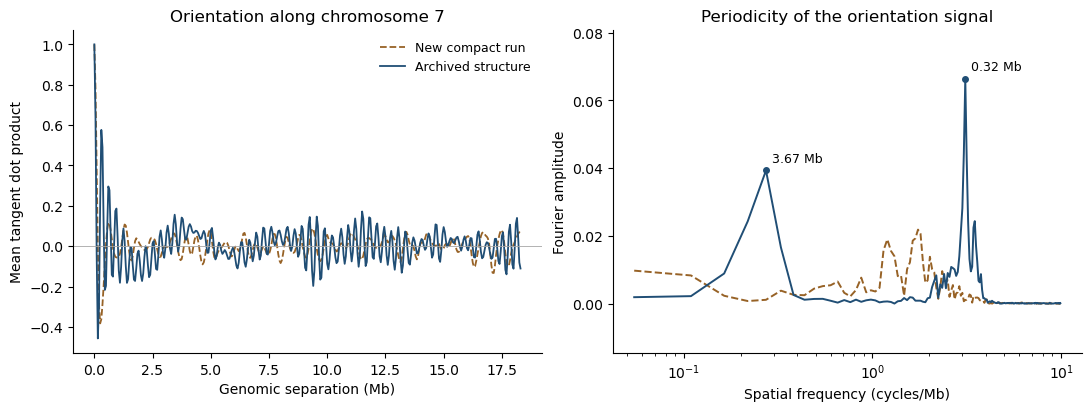

In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10.8, 4), layout="constrained")
s = np.arange(len(ref_op)) * BIN_MB
for op, amp, label, color, ls in [(new_op, amp_new, f"New {RUN} run", "#976226", "--"),
                                  (ref_op, amp_ref, "Archived structure", "#204e75", "-")]:
    a.plot(s[:len(s)//2], op[:len(s)//2], color=color, ls=ls, label=label, lw=1.3)
    b.plot(freq[1:], amp[1:], color=color, ls=ls, label=label, lw=1.4)
a.axhline(0, color="0.65", lw=0.6)
a.set(xlabel="Genomic separation (Mb)", ylabel="Mean tangent dot product", title="Orientation along chromosome 7")
b.set(xscale="log", xlabel="Spatial frequency (cycles/Mb)", ylabel="Fourier amplitude", title="Periodicity of the orientation signal")
for i in prominent:
    b.plot(freq[i], amp_ref[i], "o", color="#204e75", ms=4)
    b.annotate(f"{1/freq[i]:.2f} Mb", (freq[i], amp_ref[i]), xytext=(4, 6), textcoords="offset points", fontsize=9)
b.margins(y=0.22)
for ax in (a, b):
    ax.spines[["right", "top"]].set_visible(False)
a.legend(frameon=False, fontsize=9)
plt.show()

The two strongest peaks of the archived 15-minute structure correspond to periods of **0.32 Mb and 3.67 Mb**. They are consistent with nested helical order, but do not determine handedness. The short anneal starts from another folded structure and need not reproduce these periods. At 50 kb per bead, periods below 100 kb are not resolvable.

The archived coordinates are from `Figures-50Kb/Structures/`; the bundled text files specify the chromosome 7 type sequence and 15-minute interactions. For the model and annealing study, see [Contessoto et al., PNAS (2025)](https://doi.org/10.1073/pnas.2425225122); for the experimental DT40 time course, [Gibcus et al., Science (2018)](https://doi.org/10.1126/science.aao6135); and for OpenMiChroM, [Oliveira Junior et al., JMB (2021)](https://doi.org/10.1016/j.jmb.2020.10.034).